# Homework 3

In [34]:
import sys, os
import numpy as np
import scipy
import skimage

In [35]:
%matplotlib inline
import matplotlib.pyplot as plt

In [36]:
# MAX_ITERS = 10
TOL = 1.0e-8

## LU Factorization

#### Gaussian Elimination

This section is based on lectures 20-22 in Trefethen.

If you are unfamiliar with Gaussian elimination or need a refresher, watch [this Khan Academy video](https://www.khanacademy.org/math/precalculus/precalc-matrices/row-echelon-and-gaussian-elimination/v/matrices-reduced-row-echelon-form-2).

Let's use Gaussian Elimination by hand to review:

A =
 \begin{pmatrix}
  1 & -2 & -2 & -3 \\
  3 & -9 & 0 & -9 \\
  -1 & 2 & 4 & 7  \\
  -3 & -6 & 26 & 2
 \end{pmatrix}

#### Answer:

$$ LU = \begin{bmatrix} 1 & 0 & 0 & 0\\ 3 & 1 & 0 & 0 \\ -1 & 0 & 1 & 0 \\ -3 & 4 & -2 & 1\end{bmatrix} \cdot \begin{bmatrix} 1 & -2 & -2 & -3 \\ 0 & -3 & 6 & 0 \\ 0 & 0 & 2 & 4 \\ 0 & 0 & 0 & 1 \end{bmatrix}$$

Above example is from Lectures 20, 21 of Trefethen.

**Gaussian Elimination** transform a linear system into an upper triangular one by applying linear transformations on the left.  It is *triangular triangularization*.

$ L_{m-1} \dots L_2 L_1 A = U $

L is *unit lower-triangular*: all diagonal entries are 1

In [37]:
def LU(A):
    U = np.copy(A)
    m, n = A.shape
    L = np.eye(n)
    for k in range(n-1):
        for j in range(k+1,n):
            L[j,k] = U[j,k]/U[k,k]
            U[j,k:n] -= L[j,k] * U[k,k:n]
    return L, U

In [38]:
A = np.array([[2,1,1,0],[4,3,3,1],[8,7,9,5],[6,7,9,8]]).astype(float)

In [39]:
L, U = LU(A)

In [40]:
np.allclose(A, L @ U)

True

The LU factorization is useful!

Solving Ax = b becomes LUx = b:
1. find A = LU
2. solve Ly = b
3. solve Ux = y

**Work**

Work for Gaussian Elimination: $2\cdot\frac{1}{3} n^3$

**Memory**

Above, we created two new matrices, $L$ and $U$.  However, we can store the values of $L$ and $U$ in our matrix A (overwriting the original matrix).  Since the diagonal of $L$ is all $1$s, it doesn't need to be stored.  Doing factorizations or computations **in-place** is a common technique in numerical linear algebra to save memory.  Note: you wouldn't want to do this if you needed to use your original matrix $A$ again in the future.  One of the homework questions is to rewrite the LU method to operate in place.

Consider the matrix $$ A = \begin{bmatrix} 10^{-20} & 1 \\ 1 & 1 \end{bmatrix} $$

In [41]:
A = np.array([[1e-20, 1], [1,1]])

By hand, use Gaussian Elimination to calculate what L and U are:

#### Answer

In [42]:
#Exercise: 
"""
    First operation is -1/10^-20 * R1 basically meaning the lower matrix is now
    [1 0]
    [10^20 1] (10^20 b/c of sign change and 1/10^-20 = 10^20)

    Now the upper matrix is 
    U = [10^-20 1]
        [0 1 - 10^20]
    
    So now we can set L1 and U1 to check our method
"""
L1 = np.array([[1, 0], [10**20, 1]])
U1 = np.array([[10**-20, 1], [0, 1 - 10**20]])

In [43]:
np.set_printoptions(suppress=True)

In [44]:
#Exercise:
L1, U1

(array([[1, 0],
        [100000000000000000000, 1]], dtype=object),
 array([[1e-20, 1],
        [0, -99999999999999999999]], dtype=object))

In [45]:
L2, U2 = LU(A)

In [46]:
L2, U2

(array([[1.e+00, 0.e+00],
        [1.e+20, 1.e+00]]),
 array([[ 1.e-20,  1.e+00],
        [ 0.e+00, -1.e+20]]))

In [47]:
np.allclose(L1, L2)

True

In [48]:
np.allclose(U1, U2)

True

In [49]:
np.allclose(A, L2 @ U2)

False

This is the motivation for $LU$ factorization **with pivoting**.

This also illustrates that LU factorization is *stable*, but not *backward stable*. (spoiler alert: even with partial pivoting, LU is "explosively unstable" for certain matrices, yet stable in practice)

#### Stability

An algorithm $\hat{f}$ for a problem $f$ is **stable** if for each $x$,
$$ \frac{\lVert \hat{f}(x) - f(y) \rVert}{ \lVert f(y) \rVert } = \mathcal{O}(\varepsilon_{machine}) $$

for some $y$ with
$$ \frac{\lVert y - x \rVert }{\lVert x \rVert} = \mathcal{O}(\varepsilon_{machine}) $$

**A stable algorithm gives nearly the right answer to nearly the right question** (Trefethen, pg 104)

To translate that:
- right question: $x$
- nearly the right question: $y$
- right answer: $f$
- right answer to nearly the right question: $f(y)$

#### Backwards Stability

Backwards stability is both **stronger** and **simpler** than stability. 

An algorithm $\hat{f}$ for a problem $f$ is **backwards stable** if for each $x$,
$$ \hat{f}(x) = f(y) $$

for some $y$ with
$$ \frac{\lVert y - x \rVert }{\lVert x \rVert} = \mathcal{O}(\varepsilon_{machine}) $$

**A backwards stable algorithm gives exactly the right answer to nearly the right question** (Trefethen, pg 104)

Translation:

- right question: $x$
- nearly the right question: $y$
- right answer: $f$
- right answer to nearly the right question: $f(y)$

### LU factorization with Partial Pivoting

Let's now look at the matrix $$ \hat{A} = \begin{bmatrix} 1 & 1 \\ 10^{-20} & 1 \end{bmatrix} $$

In [50]:
A = np.array([[1,1], [1e-20, 1]])

By hand, use Gaussian Elimination to calculate what L and U are:

#### Answer

In [51]:
#Exercise:
L1, U1 = np.array([[1, 0],[10**-20, 1]]), np.array([[1, 1],[0, 1 - 10**-20]])

In [52]:
L2, U2 = LU(A)

In [53]:
np.allclose(A, L2 @ U2)

True

Idea: We can switch the order of the rows around to get more stable answers! This is equivalent to multiplying by a permutation matrix $P$.  For instance,

$$\begin{bmatrix} 0 & 1 \\ 1 & 0 \end{bmatrix} \cdot \begin{bmatrix} 10^{-20} & 1 \\ 1 & 1 \end{bmatrix} =  \begin{bmatrix} 1 & 1 \\ 10^{-20} & 1 \end{bmatrix} $$

$$ PA = \hat{A} $$

Apply Gaussian elimination to $PA$.

At each step, choose the largest value in column k, and move that row to be row k.

#### Homework

In [54]:
def swap(a,b):
    temp = np.copy(a)
    a[:] = b
    b[:] = temp

a=np.array([1,2,3])
b=np.array([3,2,1])
swap(a,b)
a,b

(array([3, 2, 1]), array([1, 2, 3]))

In [55]:
#Exercise: re-write the LU factorization above to use pivoting
""" 
# code from above
def LU(A):
    U = np.copy(A)
    m, n = A.shape
    L = np.eye(n)
    for k in range(n-1):
        for j in range(k+1,n):
            L[j,k] = U[j,k]/U[k,k]
            U[j,k:n] -= L[j,k] * U[k,k:n]
    return L, U 
"""

# Basically same idea of gaussian elimination for finding L and U but we use partial pivoting for numerical stability
def LU_pivot(A: np.ndarray) -> (np.ndarray, np.ndarray):
    U = np.array(A, dtype=float, copy=True)
    m, n = A.shape
    L = np.eye(n)
    P = np.eye(n)

    for k in range(n-1):
        # Find the row with the largest pivot
        p = k + np.argmax(np.abs(U[k:n, k]))

        # Swap rows if necessary
        if p != k:
            swap(U[k], U[p])
            swap(P[k], P[p])

            # Swap previous multipliers in L
            swap(L[k, :k], L[p, :k])

        # Perform Gaussian elimination
        for j in range(k+1, n):
            L[j, k] = U[j, k] / U[k, k]
            U[j, k:n] -= L[j, k] * U[k, k:n]

    return L, U, P


#### Example

In [56]:
A = np.array([[2,1,1,0],[4,3,3,1],[8,7,9,5],[6,7,9,8]]).astype(float)

In [57]:
L, U, P = LU_pivot(A)

Can compare below to answers in Trefethen, page 159:

In [58]:
A

array([[2., 1., 1., 0.],
       [4., 3., 3., 1.],
       [8., 7., 9., 5.],
       [6., 7., 9., 8.]])

In [59]:
U

array([[ 8.        ,  7.        ,  9.        ,  5.        ],
       [ 0.        ,  1.75      ,  2.25      ,  4.25      ],
       [ 0.        ,  0.        , -0.85714286, -0.28571429],
       [ 0.        ,  0.        ,  0.        ,  0.66666667]])

In [60]:
P

array([[0., 0., 1., 0.],
       [0., 0., 0., 1.],
       [0., 1., 0., 0.],
       [1., 0., 0., 0.]])

**Partial pivoting** permutes the rows. It is such a universal practice, that this is usually what is meant by *LU factorization*.

**Complete pivoting** permutes the rows and columns.  Complete pivoting is significantly time-consuming and rarely used in practice.

#### Example

Consider the system of equations:

$$ \begin{bmatrix} 1 & 0 & 0  & 0 & 0 & 1 \\ -1 & 1 & 0  & 0 & 0 & 1 \\ -1 & -1 & 1  & 0 & 0 & 1 \\ -1 & -1 & -1  & 1 & 0 & 1  \\  -1 & -1 & -1  & -1 & 1 & 1 \\ -1 & -1 & -1  & -1 & -1 & 1 \end{bmatrix} \mathbf{x} = \begin{bmatrix} 1 \\ 1 \\ 1  \\ 1 \\ 2 \\ 1 \end{bmatrix} $$

In [61]:
def make_matrix(n):
    A = np.eye(n)
    for i in range(n):
        A[i,-1] = 1
        for j in range(i):
            A[i,j] = -1
    return A 

In [62]:
def make_vector(n):
    b = np.ones(n)
    b[-2] = 2
    return b

In [63]:
make_vector(7)

array([1., 1., 1., 1., 1., 2., 1.])

#### Exercise

Exercise: Let's use Gaussian Elimination on the $5 \times 5$ system.

Scipy has this funtionality as well.  Let's look at the solution for the last 5 equations with $n=10,\,20,\,30,\,40,\,50,\,60$.

In [66]:
from scipy.linalg import solve

[-0.00195312 -0.00390625 -0.0078125  -0.015625   -0.03125    -0.0625
 -0.125      -0.25        0.5         1.00195312]
[-0.00000191 -0.00000381 -0.00000763 -0.00001526 -0.00003052 -0.00006104
 -0.00012207 -0.00024414 -0.00048828 -0.00097656 -0.00195312 -0.00390625
 -0.0078125  -0.015625   -0.03125    -0.0625     -0.125      -0.25
  0.5         1.00000191]
[-0.         -0.         -0.00000001 -0.00000001 -0.00000003 -0.00000006
 -0.00000012 -0.00000024 -0.00000048 -0.00000095 -0.00000191 -0.00000381
 -0.00000763 -0.00001526 -0.00003052 -0.00006104 -0.00012207 -0.00024414
 -0.00048828 -0.00097656 -0.00195312 -0.00390625 -0.0078125  -0.015625
 -0.03125    -0.0625     -0.125      -0.25        0.5         1.        ]
[-0.         -0.         -0.         -0.         -0.         -0.
 -0.         -0.         -0.         -0.         -0.         -0.
 -0.00000001 -0.00000001 -0.00000003 -0.00000006 -0.00000012 -0.00000024
 -0.00000048 -0.00000095 -0.00000191 -0.00000381 -0.00000763 -0.00001526
 -

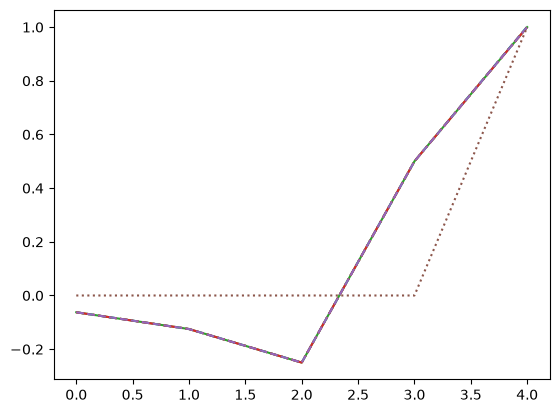

In [67]:
for n, ls in zip(range(10, 70, 10), ['--', ':', '-', '-.', '--', ':']):
    soln = scipy.linalg.lu_solve(scipy.linalg.lu_factor(make_matrix(n)), make_vector(n))
    plt.plot(soln[-5:], ls)
    print(soln)

What is going on when $n=60$?

**Theorem**: Let the factorization $PA = LU$ of a matrix A be computed by Gaussian Elimination with partial pivoting.  The *computed* (by a computer with Floating Point Arithmetic) matrices $\hat{P}$, $\hat{L}$, and $\hat{U}$ satisfy

$$\hat{L}\hat{U} = \hat{P} A + \delta A, \quad \frac{\delta A}{A} = \mathcal{O}(\rho \varepsilon_{machine}) $$

where $\rho$ is the *growth factor*, 

$$\rho = \frac{max_{i,j} \lvert u_{ij} \rvert }{max_{i,j} \lvert a_{ij} \rvert } $$

For our matrix above, $\rho = 2^{m-1}$

#### Unstable in theory, stable in practice

Stability of most algorithms (such as QR) is straightforward.  Not the case for Gaussian Elimination with partial pivoting.  Instability in Gaussian elimination (with or without pivoting) arises only if L and/or U is large relative to the size of A.

Trefethen: "Despite examples like (22.4), Gaussian elimination with partial pivoting is utterly stable in practice... In fifty years of computing, no matrix problems that excite an explosive instability are known to have arisen under natural circumstances." [although can easily be constructed as contrived examples]

Although some matrices cause instability, but extraordinarily small proportion of all matrices so "never" arise in practice for statistical reasons.  "If you pick a billion matrices at random, you will almost certainly not find one for which Gaussian elimination is unstable."

### Further Reading
- Gaussian Elimination/LU factorization-- Trefethn Lecture 20
- Pivoting -- Trefethn Lecture 21
- Stability of Gaussian Elimination -- Trefethn Lecture 22